In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel(r"C:\Users\Dell\Desktop\data\pizza_sales_excel_file.xlsx")


In [ ]:
print(pd)
print(np)
print(plt)
print(sns)

<module 'pandas' from 'c:\\Users\\Dell\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\pandas\\__init__.py'>
<module 'numpy' from 'c:\\Users\\Dell\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\numpy\\__init__.py'>
<module 'matplotlib.pyplot' from 'c:\\Users\\Dell\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\matplotlib\\pyplot.py'>
<module 'seaborn' from 'c:\\Users\\Dell\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\seaborn\\__init__.py'>


In [ ]:
#قبل فحص أي ملف بنبدأ عملية تنضيف نعرف من خلالها فيه مشكلة في الداتا قبل ما نجيب القيم المرادة منها ولا لا
df.info()        # بيوريكي: كام عمود، نوع كل عمود (رقم/نص/تاريخ)، وكام قيمة فاضية في كل عمود
df.describe()     # بيوريكي: أقل قيمة، أكبر قيمة، المتوسط... للأعمدة الرقمية
df.head(10)       # تشوفي أول 10 صفوف بعينك عشان تحسي بشكل الداتا

<class 'pandas.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   pizza_id           48620 non-null  int64         
 1   order_id           48620 non-null  int64         
 2   pizza_name_id      48620 non-null  str           
 3   quantity           48620 non-null  int64         
 4   order_date         48620 non-null  datetime64[us]
 5   order_time         48620 non-null  object        
 6   unit_price         48620 non-null  float64       
 7   total_price        48620 non-null  float64       
 8   pizza_size         48620 non-null  str           
 9   pizza_category     48620 non-null  str           
 10  pizza_ingredients  48620 non-null  str           
 11  pizza_name         48620 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(3), object(1), str(5)
memory usage: 4.5+ MB


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza
5,6,2,thai_ckn_l,1,2015-01-01,11:57:40,20.75,20.75,L,Chicken,"Chicken, Pineapple, Tomatoes, Red Peppers, Tha...",The Thai Chicken Pizza
6,7,3,ital_supr_m,1,2015-01-01,12:12:28,16.50,16.50,M,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
7,8,3,prsc_argla_l,1,2015-01-01,12:12:28,20.75,20.75,L,Supreme,"Prosciutto di San Daniele, Arugula, Mozzarella...",The Prosciutto and Arugula Pizza
8,9,4,ital_supr_m,1,2015-01-01,12:16:31,16.50,16.50,M,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
9,10,5,ital_supr_m,1,2015-01-01,12:21:30,16.50,16.50,M,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza


In [ ]:
#لاحظنا ان الوقت باع الاوردر مكتوب ك object مش توقيت ف لازم نبدلها عشان بايثون يتعرف عليه ك رقم مش ك كلام نصي
df["order_time"] = pd.to_datetime(df["order_time"], format="%H:%M:%S")
df["order_time"].info()

<class 'pandas.Series'>
RangeIndex: 48620 entries, 0 to 48619
Series name: order_time
Non-Null Count  Dtype         
--------------  -----         
48620 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 380.0 KB


In [ ]:
#يعدين بندور على الmissing values 
df.isnull().sum()          # كام قيمة فاضية في كل عمود
df.isnull().sum() / len(df) * 100   # نسبة الفاضي من كل عمود


pizza_id             0.0
order_id             0.0
pizza_name_id        0.0
quantity             0.0
order_date           0.0
order_time           0.0
unit_price           0.0
total_price          0.0
pizza_size           0.0
pizza_category       0.0
pizza_ingredients    0.0
pizza_name           0.0
dtype: float64

In [ ]:
#ندور عالمتكرر
df.duplicated().sum()      # كام صف مكرر بالظبط

np.int64(0)

In [ ]:
#ندور في الأعمدة الرقمية عن القيم الشاذة أو البعيدة outliers
numeric_cols = df.select_dtypes(include=np.number).columns
numeric_cols


Index(['pizza_id', 'order_id', 'quantity', 'unit_price', 'total_price'], dtype='str')

In [ ]:
object_cols = df.select_dtypes(include=str).columns
object_cols

Index(['pizza_name_id', 'pizza_size', 'pizza_category', 'pizza_ingredients',
       'pizza_name'],
      dtype='str')

In [ ]:
cols=['pizza_id', 'order_id', 'quantity', 'unit_price', 'total_price'] 
 
df[cols].describe()
 # اشمل واعم لمعرفة جميع الحسابات
 

,pizza_id,order_id,quantity,unit_price,total_price
count,48620.000000,48620.000000,48620.000000,48620.000000,48620.000000
mean,24310.500000,10701.479761,1.019622,16.494132,16.821474
std,14035.529381,6180.119770,0.143077,3.621789,4.437398
min,1.000000,1.000000,1.000000,9.750000,9.750000
25%,12155.750000,5337.000000,1.000000,12.750000,12.750000
50%,24310.500000,10682.500000,1.000000,16.500000,16.500000
75%,36465.250000,16100.000000,1.000000,20.250000,20.500000
max,48620.000000,21350.000000,4.000000,35.950000,83.000000


In [ ]:
df["pizza_size"].unique()
df["pizza_category"].value_counts()

pizza_category
Classic    14579
Supreme    11777
Veggie     11449
Chicken    10815
Name: count, dtype: int64

In [ ]:
df["pizza_name"].value_counts()

pizza_name
The Classic Deluxe Pizza                      2416
The Barbecue Chicken Pizza                    2372
The Hawaiian Pizza                            2370
The Pepperoni Pizza                           2369
The Thai Chicken Pizza                        2315
The California Chicken Pizza                  2302
The Spicy Italian Pizza                       1887
The Sicilian Pizza                            1887
The Southwest Chicken Pizza                   1885
The Four Cheese Pizza                         1850
The Italian Supreme Pizza                     1849
The Big Meat Pizza                            1811
The Vegetables + Vegetables Pizza             1510
The Mexicana Pizza                            1456
The Napolitana Pizza                          1451
The Spinach and Feta Pizza                    1432
The Prosciutto and Arugula Pizza              1428
The Pepper Salami Pizza                       1422
The Italian Capocollo Pizza                   1414
The Greek Pizza     

In [ ]:
#عشان نطلع الunique في كل عامود بدل ما نكتبهم واحد واحد بنعمل لوب يعدي على عامود عامود يتحقق من اليونيك بتاعه
for col in cols:
    print(f"--- {col} ---")
    print(df[col].unique())
    print()

--- pizza_id ---
[    1     2     3 ... 48618 48619 48620]

--- order_id ---
[    1     2     3 ... 21348 21349 21350]

--- quantity ---
[1 2 3 4]

--- unit_price ---
[13.25 16.   18.5  20.75 16.5  12.75 12.   12.5  20.5  20.25 16.75 15.25
 17.95 16.25 14.75  9.75 17.5  10.5  25.5  11.   14.5  12.25 21.   23.65
 35.95]

--- total_price ---
[13.25 16.   18.5  20.75 16.5  12.75 12.   12.5  20.5  20.25 16.75 15.25
 17.95 16.25 14.75 32.    9.75 17.5  10.5  25.5  11.   14.5  12.25 21.
 62.25 41.5  50.25 23.65 24.   33.5  35.9  25.   19.5  37.5  37.   41.
 33.   40.5  24.5  47.3  22.   35.95 29.   29.5  26.5  48.75 32.5  30.5
 48.   51.   36.   35.   83.   61.5  49.5  55.5 ]



In [ ]:
#بتوريني كل قيمة وعدد مرات تكررارها
for col in cols:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- pizza_id ---
pizza_id
1        1
2        1
3        1
4        1
5        1
        ..
48616    1
48617    1
48618    1
48619    1
48620    1
Name: count, Length: 48620, dtype: int64

--- order_id ---
order_id
10760    21
18845    21
13906    15
14304    15
17464    15
         ..
21338     1
21339     1
21341     1
21349     1
21350     1
Name: count, Length: 21350, dtype: int64

--- quantity ---
quantity
1    47693
2      903
3       21
4        3
Name: count, dtype: int64

--- unit_price ---
unit_price
20.75    8685
12.00    5600
16.00    4474
16.75    4294
16.50    4040
12.50    3328
20.25    3032
12.75    2507
20.50    1998
18.50    1359
17.95    1273
16.25    1114
10.50    1001
12.25     830
9.75      739
15.25     712
14.75     577
11.00     570
25.50     544
23.65     480
13.25     473
14.50     391
17.50     381
21.00     190
35.95      28
Name: count, dtype: int64

--- total_price ---
total_price
20.75    8485
12.00    5465
16.00    4428
16.75    4211
16.50    3970
12.50

In [ ]:
ingerdiants_categories = df["pizza_ingredients"].str.split(",").explode()
ingerdiants_categories

0                Sliced Ham
0                 Pineapple
0         Mozzarella Cheese
1                 Pepperoni
1                 Mushrooms
                ...        
48619           Red Peppers
48619         Green Peppers
48619              Tomatoes
48619            Red Onions
48619        Barbecue Sauce
Name: pizza_ingredients, Length: 267576, dtype: str

In [ ]:
ingerdiants_categories = ingerdiants_categories.str.strip() #سبليت عشان اتأكد مفيش فراغات أو مسطرة تخلي نفس الصنف يتكرر تاني كأنه صنف جديد
ingerdiants_categories 

0               Sliced Ham
0                Pineapple
0        Mozzarella Cheese
1                Pepperoni
1                Mushrooms
               ...        
48619          Red Peppers
48619        Green Peppers
48619             Tomatoes
48619           Red Onions
48619       Barbecue Sauce
Name: pizza_ingredients, Length: 267576, dtype: str

In [ ]:
count_for_each= ingerdiants_categories.value_counts()
count_for_each

pizza_ingredients
Garlic                27422
Tomatoes              26601
Red Onions            19547
Red Peppers           16284
Mozzarella Cheese     10333
                      ...  
Brie Carre Cheese       480
Prosciutto              480
Caramelized Onions      480
Pears                   480
Thyme                   480
Name: count, Length: 65, dtype: int64

In [ ]:
percentage_for_each= ingerdiants_categories.value_counts() #(normalize=True)*100 #نورمالايز بيساوي ترو معناه تقسم الدالة اللي طلعت على العدد الكلي تلقائيا عشان يطلعلك النسبة كام من مئة وبعدين نضرب في مية عشان بقى اعداد صحيحة كبيرة مش كسور عشرية صغيرة صعبة الحسب
total_orders= len(df)
percentage_for_each
percentage_in_orders= (percentage_for_each / total_orders * 100).round(2)
print(percentage_in_orders.sort_values(ascending=False))

pizza_ingredients
Garlic                56.40
Tomatoes              54.71
Red Onions            40.20
Red Peppers           33.49
Mozzarella Cheese     21.25
                      ...  
Brie Carre Cheese      0.99
Prosciutto             0.99
Caramelized Onions     0.99
Pears                  0.99
Thyme                  0.99
Name: count, Length: 65, dtype: float64


In [ ]:
each_ingerediant_summary=pd.DataFrame({
   "ingerdiants_categories":count_for_each.index,
   "count_for_each":count_for_each.values,
   "percentage_for_each":(count_for_each/len(df)*100).round(2),
}).sort_values("count_for_each", ascending=False).reset_index(drop=True)
each_ingerediant_summary

,ingerdiants_categories,count_for_each,percentage_for_each
0,Garlic,27422,56.40
1,Tomatoes,26601,54.71
2,Red Onions,19547,40.20
3,Red Peppers,16284,33.49
4,Mozzarella Cheese,10333,21.25
...,...,...,...
60,Brie Carre Cheese,480,0.99
61,Prosciutto,480,0.99
62,Caramelized Onions,480,0.99
63,Pears,480,0.99


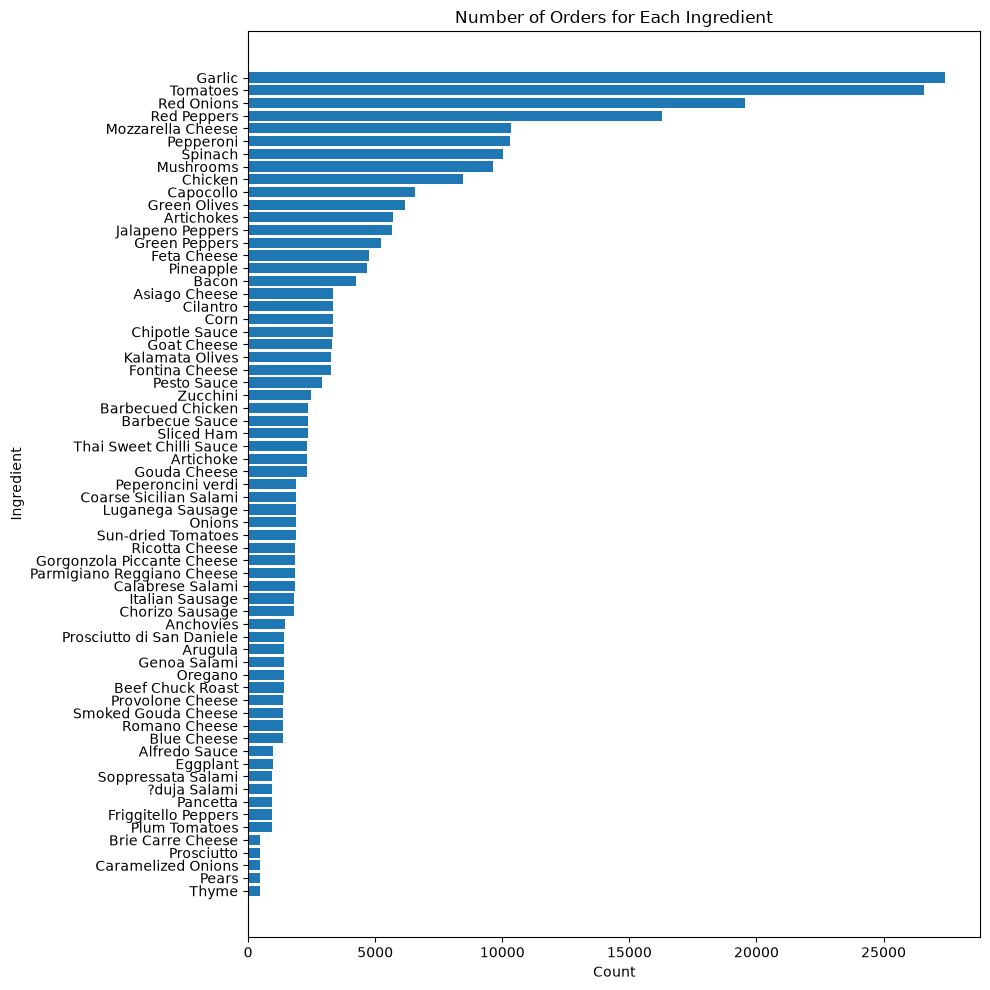

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
plt.barh(each_ingerediant_summary["ingerdiants_categories"],each_ingerediant_summary["count_for_each"])
plt.title("Number of Orders for Each Ingredient")
plt.xlabel("Count")
plt.ylabel("Ingredient")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

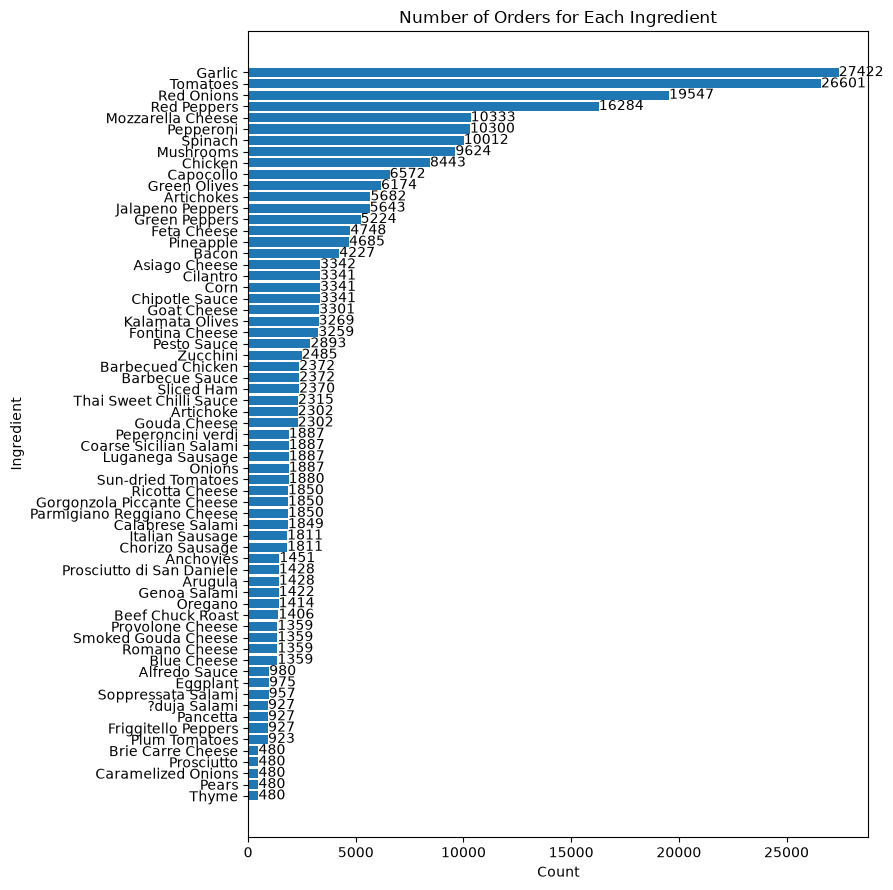

In [ ]:
plt.figure(figsize=(10, 10))
bars = plt.barh(each_ingerediant_summary["ingerdiants_categories"],
                each_ingerediant_summary["count_for_each"])
plt.title("Number of Orders for Each Ingredient")
plt.xlabel("Count")
plt.ylabel("Ingredient")
plt.gca().invert_yaxis()
for bar in bars:
    plt.text(bar.get_width(),bar.get_y() + bar.get_height() / 2,f"{int(bar.get_width())}",va="center")
plt.tight_layout()
plt.show()

In [ ]:
most_ordered_pizza=df.groupby("pizza_name")["quantity"].sum().sort_values(ascending=False)
most_ordered_pizza

pizza_name
The Classic Deluxe Pizza                      2453
The Barbecue Chicken Pizza                    2432
The Hawaiian Pizza                            2422
The Pepperoni Pizza                           2418
The Thai Chicken Pizza                        2371
The California Chicken Pizza                  2370
The Sicilian Pizza                            1938
The Spicy Italian Pizza                       1924
The Southwest Chicken Pizza                   1917
The Big Meat Pizza                            1914
The Four Cheese Pizza                         1902
The Italian Supreme Pizza                     1884
The Vegetables + Vegetables Pizza             1526
The Mexicana Pizza                            1484
The Napolitana Pizza                          1464
The Prosciutto and Arugula Pizza              1457
The Pepper Salami Pizza                       1446
The Spinach and Feta Pizza                    1446
The Italian Capocollo Pizza                   1438
The Greek Pizza     

In [ ]:
top_10=each_ingerediant_summary.head(10)
top_10

,ingerdiants_categories,count_for_each,percentage_for_each
0,Garlic,27422,56.40
1,Tomatoes,26601,54.71
2,Red Onions,19547,40.20
3,Red Peppers,16284,33.49
4,Mozzarella Cheese,10333,21.25
5,Pepperoni,10300,21.18
6,Spinach,10012,20.59
7,Mushrooms,9624,19.79
8,Chicken,8443,17.37
9,Capocollo,6572,13.52


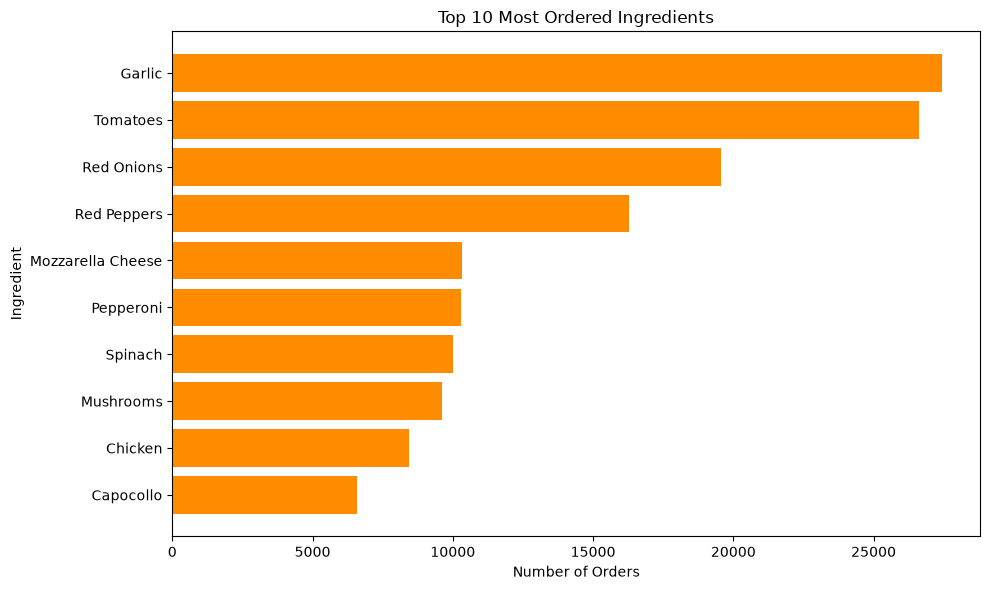

In [ ]:
top_10 = each_ingerediant_summary.head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_10["ingerdiants_categories"],top_10["count_for_each"],color="darkorange")
plt.title("Top 10 Most Ordered Ingredients")
plt.xlabel("Number of Orders")
plt.ylabel("Ingredient")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
less_10=each_ingerediant_summary.tail(10)
less_10

,ingerdiants_categories,count_for_each,percentage_for_each
55,Soppressata Salami,957,1.97
56,?duja Salami,927,1.91
57,Pancetta,927,1.91
58,Friggitello Peppers,927,1.91
59,Plum Tomatoes,923,1.90
60,Brie Carre Cheese,480,0.99
61,Prosciutto,480,0.99
62,Caramelized Onions,480,0.99
63,Pears,480,0.99
64,Thyme,480,0.99


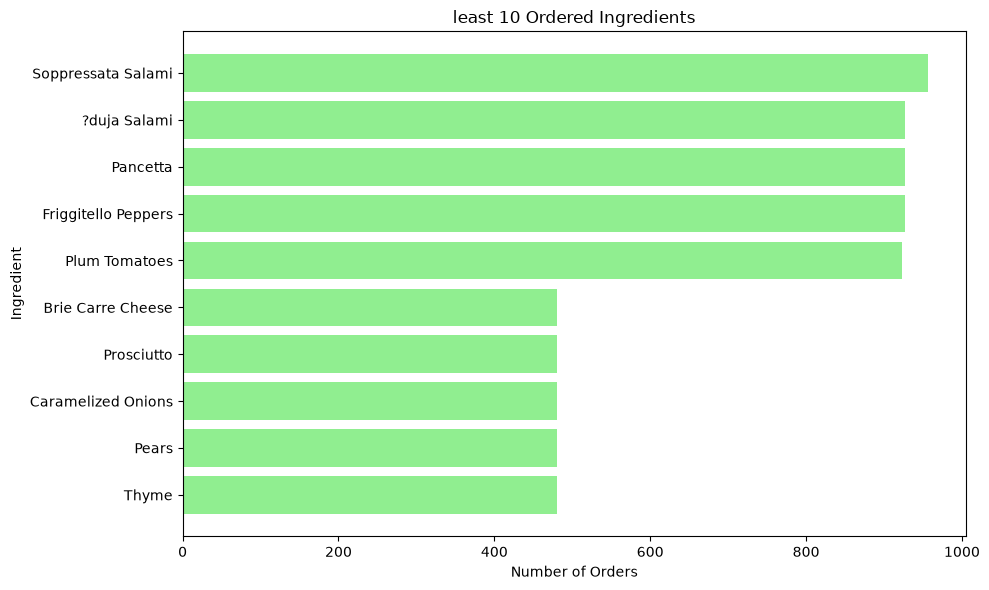

In [ ]:
less_10 = each_ingerediant_summary.tail(10)
plt.figure(figsize=(10, 6))
plt.barh(less_10["ingerdiants_categories"],less_10["count_for_each"],color="lightgreen")
plt.title("least 10 Ordered Ingredients")
plt.xlabel("Number of Orders")
plt.ylabel("Ingredient")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["day_name"] = df["order_date"].dt.day_name()
df["order_date"]
df["day_name"]

0        Thursday
1        Thursday
2        Thursday
3        Thursday
4        Thursday
           ...   
48615    Thursday
48616    Thursday
48617    Thursday
48618    Thursday
48619    Thursday
Name: day_name, Length: 48620, dtype: str

In [ ]:
df["day_type"] = np.where(
    df["day_name"].isin(["Thursday", "Friday"]),
    "Holiday",
    "Normal")
df["day_type"]

0        Holiday
1        Holiday
2        Holiday
3        Holiday
4        Holiday
          ...   
48615    Holiday
48616    Holiday
48617    Holiday
48618    Holiday
48619    Holiday
Name: day_type, Length: 48620, dtype: str

In [ ]:
daily_pizza = (
    df.groupby(["order_date", "pizza_name"])["quantity"]
    .sum()
    .reset_index())
daily_pizza

,order_date,pizza_name,quantity
0,2015-01-01,The Barbecue Chicken Pizza,11
1,2015-01-01,The Big Meat Pizza,5
2,2015-01-01,The Calabrese Pizza,1
3,2015-01-01,The California Chicken Pizza,4
4,2015-01-01,The Chicken Alfredo Pizza,2
...,...,...,...
11028,2015-12-31,The Spinach Pesto Pizza,5
11029,2015-12-31,The Spinach Supreme Pizza,2
11030,2015-12-31,The Spinach and Feta Pizza,5
11031,2015-12-31,The Thai Chicken Pizza,3


In [ ]:
daily_top_pizza = (
    daily_pizza.loc[
        daily_pizza.groupby("order_date")["quantity"].idxmax()
    ]
    .reset_index(drop=True))
daily_top_pizza

,order_date,pizza_name,quantity
0,2015-01-01,The Italian Supreme Pizza,15
1,2015-01-02,The Pepperoni Pizza,12
2,2015-01-03,The California Chicken Pizza,12
3,2015-01-04,The Barbecue Chicken Pizza,11
4,2015-01-05,The Chicken Alfredo Pizza,9
...,...,...,...
353,2015-12-27,The Vegetables + Vegetables Pizza,9
354,2015-12-28,The Classic Deluxe Pizza,9
355,2015-12-29,The Big Meat Pizza,6
356,2015-12-30,The California Chicken Pizza,7


In [ ]:
top_pizza_by_days = (
    daily_top_pizza["pizza_name"]
    .value_counts()
    .reset_index())
top_pizza_by_days

,pizza_name,count
0,The Barbecue Chicken Pizza,57
1,The Hawaiian Pizza,44
2,The Pepperoni Pizza,42
3,The California Chicken Pizza,42
4,The Classic Deluxe Pizza,40
5,The Thai Chicken Pizza,23
6,The Four Cheese Pizza,20
7,The Big Meat Pizza,19
8,The Southwest Chicken Pizza,12
9,The Spicy Italian Pizza,12


In [ ]:
normal_days = df[df["day_type"] == "Normal"]
normal_top3 = (
    normal_days.groupby("pizza_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(3))
normal_top3

pizza_name
The Hawaiian Pizza            1676
The Classic Deluxe Pizza      1667
The Barbecue Chicken Pizza    1664
Name: quantity, dtype: int64

In [ ]:
Holiday_days = df[df["day_type"] == "Holiday"]
Holiday_top3 = (
   Holiday_days.groupby("pizza_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(3))
Holiday_top3


pizza_name
The Pepperoni Pizza           827
The Classic Deluxe Pizza      786
The Barbecue Chicken Pizza    768
Name: quantity, dtype: int64

In [ ]:
comparison = pd.concat(
    [
        normal_top3.rename("Normal Days"),
        Holiday_top3.rename("Holidays")
    ],
    axis=1
)
comparison

,Normal Days,Holidays
pizza_name,,
The Hawaiian Pizza,1676.0,NaN
The Classic Deluxe Pizza,1667.0,786.0
The Barbecue Chicken Pizza,1664.0,768.0
The Pepperoni Pizza,NaN,827.0


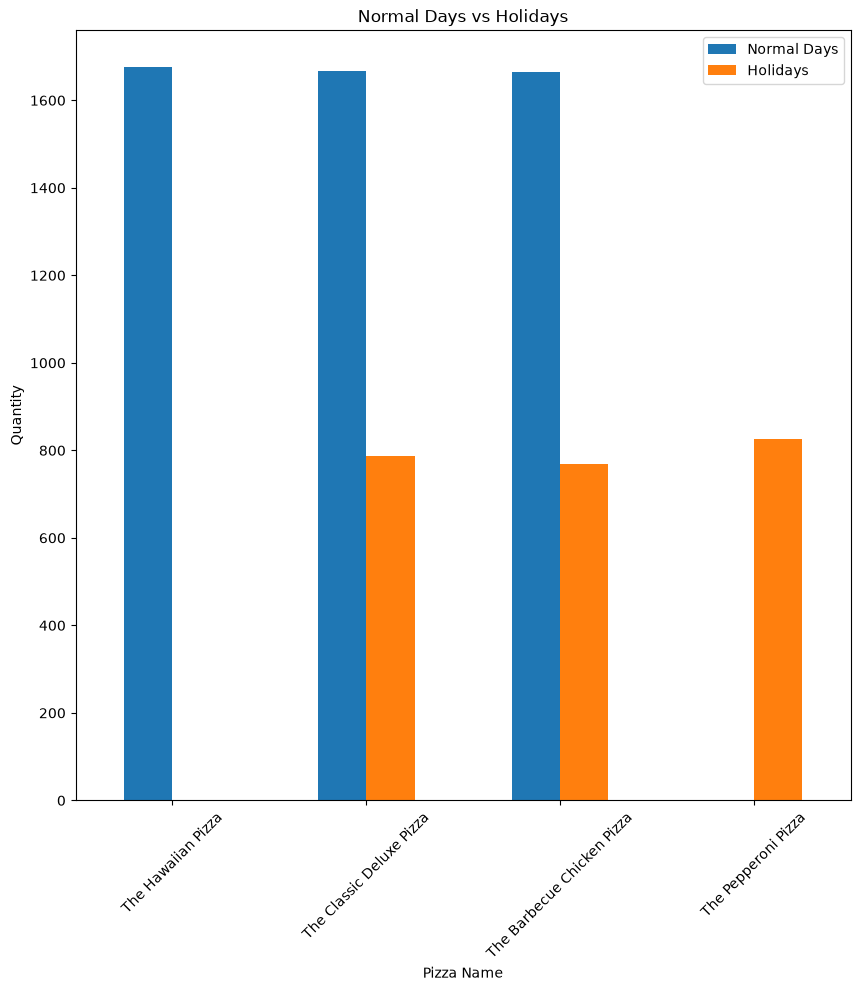

In [ ]:
comparison.plot(kind="bar", figsize=(10, 10))
plt.title("Normal Days vs Holidays")
plt.xlabel("Pizza Name")
plt.ylabel("Quantity")
plt.xticks(rotation=45)
plt.show()

In [ ]:
normal_avg = (
    df[df["day_type"] == "Normal"]
    .groupby("pizza_name")["quantity"]
    .mean()
    .sort_values(ascending=False)
    .head(3)
)

holiday_avg = (
    df[df["day_type"] == "Holiday"]
    .groupby("pizza_name")["quantity"]
    .mean()
    .sort_values(ascending=False)
    .head(3)
)
normal_avg
holiday_avg

pizza_name
The Big Meat Pizza        1.054845
The Five Cheese Pizza     1.042222
The Thai Chicken Pizza    1.030769
Name: quantity, dtype: float64